# Deep Learning: Image Classification (Monkeypox)

Import Tools

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from PIL import Image

from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

Set style and seed

In [2]:
sns.set_style('whitegrid')
np.random.seed(42)
tf.random.set_seed(42)

Data Import

In [10]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nafin59/monkeypox-skin-lesion-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'monkeypox-skin-lesion-dataset' dataset.
Path to dataset files: /kaggle/input/monkeypox-skin-lesion-dataset


In [23]:
print("Dataset folder:")

for folder in os.listdir(path):
    print(folder)

Dataset folder:
Fold1
Augmented Images
Original Images
Monkeypox_Dataset_metadata.csv


Change direktory to Original Images, because we want to preprocess the images manual

In [41]:
original_path = os.path.join(path, "Original Images", "Original Images")

for folder in os.listdir(original_path):
    folder_path = os.path.join(original_path, folder)
    if os.path.isdir(folder_path):
        print(folder, len(os.listdir(folder_path)))

Others 126
Monkey Pox 102


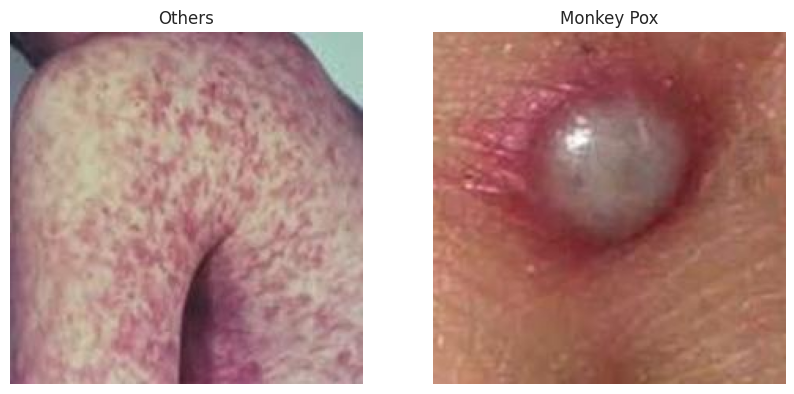

In [42]:
classes = [f for f in os.listdir(original_path)
           if os.path.isdir(os.path.join(original_path, f))]

fig, axes = plt.subplots(1, len(classes), figsize=(5 * len(classes), 5))
for ax, cls in zip(axes, classes):
    cls_path = os.path.join(original_path, cls)
    img_name = os.listdir(cls_path)[0]
    ax.imshow(Image.open(os.path.join(cls_path, img_name)))
    ax.set_title(cls)
    ax.axis("off")
plt.show()

Train test split

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    original_path,
    validation_split=0.3,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    original_path,
    validation_split=0.3,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

n = tf.data.experimental.cardinality(val_test_ds).numpy()
val_ds = val_test_ds.take(n // 2)
test_ds = val_test_ds.skip(n // 2)

class_names = train_ds.class_names
print(class_names)

Found 228 files belonging to 2 classes.
Using 160 files for training.
Found 228 files belonging to 2 classes.
Using 68 files for validation.
['Monkey Pox', 'Others']


# A. Data Understanding

In [ ]:
#

# B. Data Preparation

# C. Modeling

# D. Evaluation